<a href="https://colab.research.google.com/github/tejorishi/neur3002/blob/main/Neuro3002NeuralMechanismModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

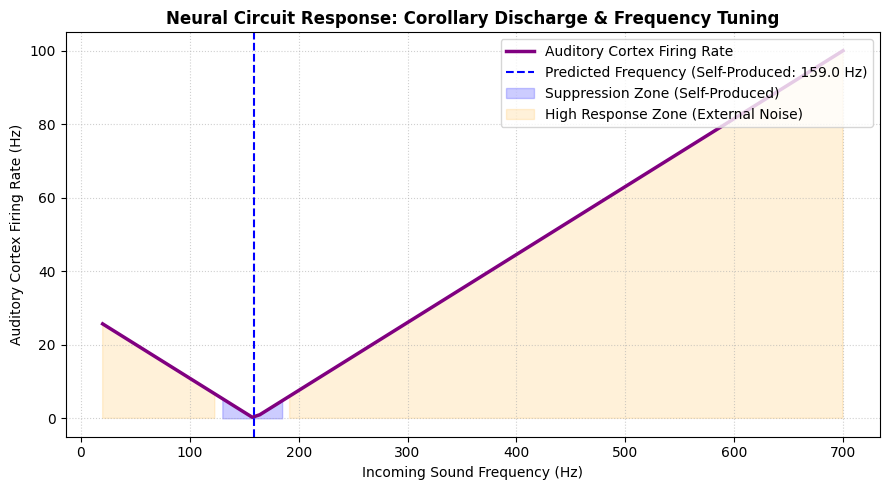

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Set up frequency range (e.g., 20 Hz to 500 Hz) - Humans can hear from 20-20,000Hz but that would look ugly on
# the graph and is easier to represent the change in firing rate from a smaller Hz.
# This provides the steps of the x-axis in the final graph - (min, max, grid steps)
frequencies = np.linspace(20, 700, 100)

# The brain's predicted frequency based on motor command (corollary discharge) - this means the predicted
# frequency of the self-made noise, which comes from the motor cortex to the auditory cortex.
# This frequency was chosen as a number around the average human voice's frequency between a man and women.

predicted_frequency = 159.0  # Hz

# Firing rate is proportional to the distance from the predicted frequency (V-shaped suppression curve)
# At f == predicted_frequency, firing rate is lowest (suppressed).
# Farther away, firing rate increases (unsuppressed external noise). This takes the absolute value of the difference
# between frequency and predicted frequency to make a baseline firing rate
firing_rate = np.abs(frequencies - predicted_frequency)

# Normalize or scale for a realistic firing rate appearance (e.g., max 100 Hz)
# This scales the firing rate to make a set the max firing rate Hz to 100 - this can be changed by
# changing '100' to a different number.
firing_rate = (firing_rate / np.max(firing_rate)) * 100

#This makes the size of the figure and makes the variables stated previously into values on the graph
# such as the color of the firing rate line and label of the line.
plt.figure(figsize=(9, 5))
plt.plot(frequencies, firing_rate, color='purple', linewidth=2.5, label='Auditory Cortex Firing Rate')

# Highlight self-produced vs external regions: This highlights the area under the line where the brain would
# decide that a noise is self-produced or external signalled by blue and orange respectively.
# This also provides some variables for the key of the graph where the different colors and predicted frequency is
# stated
plt.axvline(x=predicted_frequency, color='blue', linestyle='--', label=f'Predicted Frequency (Self-Produced: {predicted_frequency} Hz)')
plt.fill_between(frequencies, firing_rate, where=(np.abs(frequencies - predicted_frequency) < 30), color='blue', alpha=0.2, label='Suppression Zone (Self-Produced)')
plt.fill_between(frequencies, firing_rate, where=(np.abs(frequencies - predicted_frequency) >= 30), color='orange', alpha=0.15, label='High Response Zone (External Noise)')
# The following code provides the title, x and y axis, location of the legend, and more using the matplotlib.pyplot
# as plot as a downloaded library.
plt.title('Neural Circuit Response: Corollary Discharge & Frequency Tuning', fontsize=12, fontweight='bold')
plt.xlabel('Incoming Sound Frequency (Hz)', fontsize=10)
plt.ylabel('Auditory Cortex Firing Rate (Hz)', fontsize=10)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Display the plot directly in the notebook
plt.show()